# Exploring the C-MAPSS data (FD001)

This notebook looks at the raw files before any processing. The questions are simple:
what does one row contain, how long do engines live, what do the sensors look like as an
engine wears out, and which sensors carry no information at all.

The data comes from `python -m pipeline.download`, which must have been run first.

## Setup

The notebook lives in `notebooks/`, one level below the project root. Adding the root to
`sys.path` lets it import the `turbofan` package, so the files are read by the same
`load_raw` function as the rest of the project.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))

from turbofan.config import SENSOR_COLUMNS, load_params  # noqa: E402
from turbofan.data import load_raw  # noqa: E402

## A first look at the table

Each row is one engine (`unit_id`) at one flight cycle (`cycle`): three operational
settings and 21 sensor readings. In the training file, every engine is followed until it
fails, so its last row is its last cycle before failure.

In [ ]:
train = load_raw("FD001", "train")
print(f"{len(train)} rows, {train['unit_id'].nunique()} engines, {train.shape[1]} columns")
train.head()

20631 rows, 100 engines, 26 columns


,unit_id,cycle,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## How long do engines live?

The lifetime of an engine is its number of cycles, that is its last `cycle` value.

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


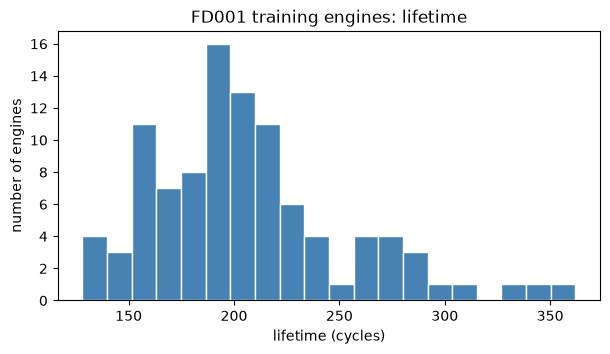

In [ ]:
lifetimes = train.groupby("unit_id")["cycle"].max()
print(lifetimes.describe().round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(lifetimes, bins=20, color="steelblue", edgecolor="white")
ax.set_xlabel("lifetime (cycles)")
ax.set_ylabel("number of engines")
ax.set_title("FD001 training engines: lifetime")
plt.show()

Lifetimes go from 128 to 362 cycles, with a median of 199. Half of the engines live
between 177 and 229 cycles; a few live much longer. A model therefore cannot just learn
"an engine fails after 200 cycles": it has to read the wear in the sensors.

## All 21 sensors of one engine over its whole life

Engine 1 lives 192 cycles. Each small plot is one sensor, cycle on the x axis.

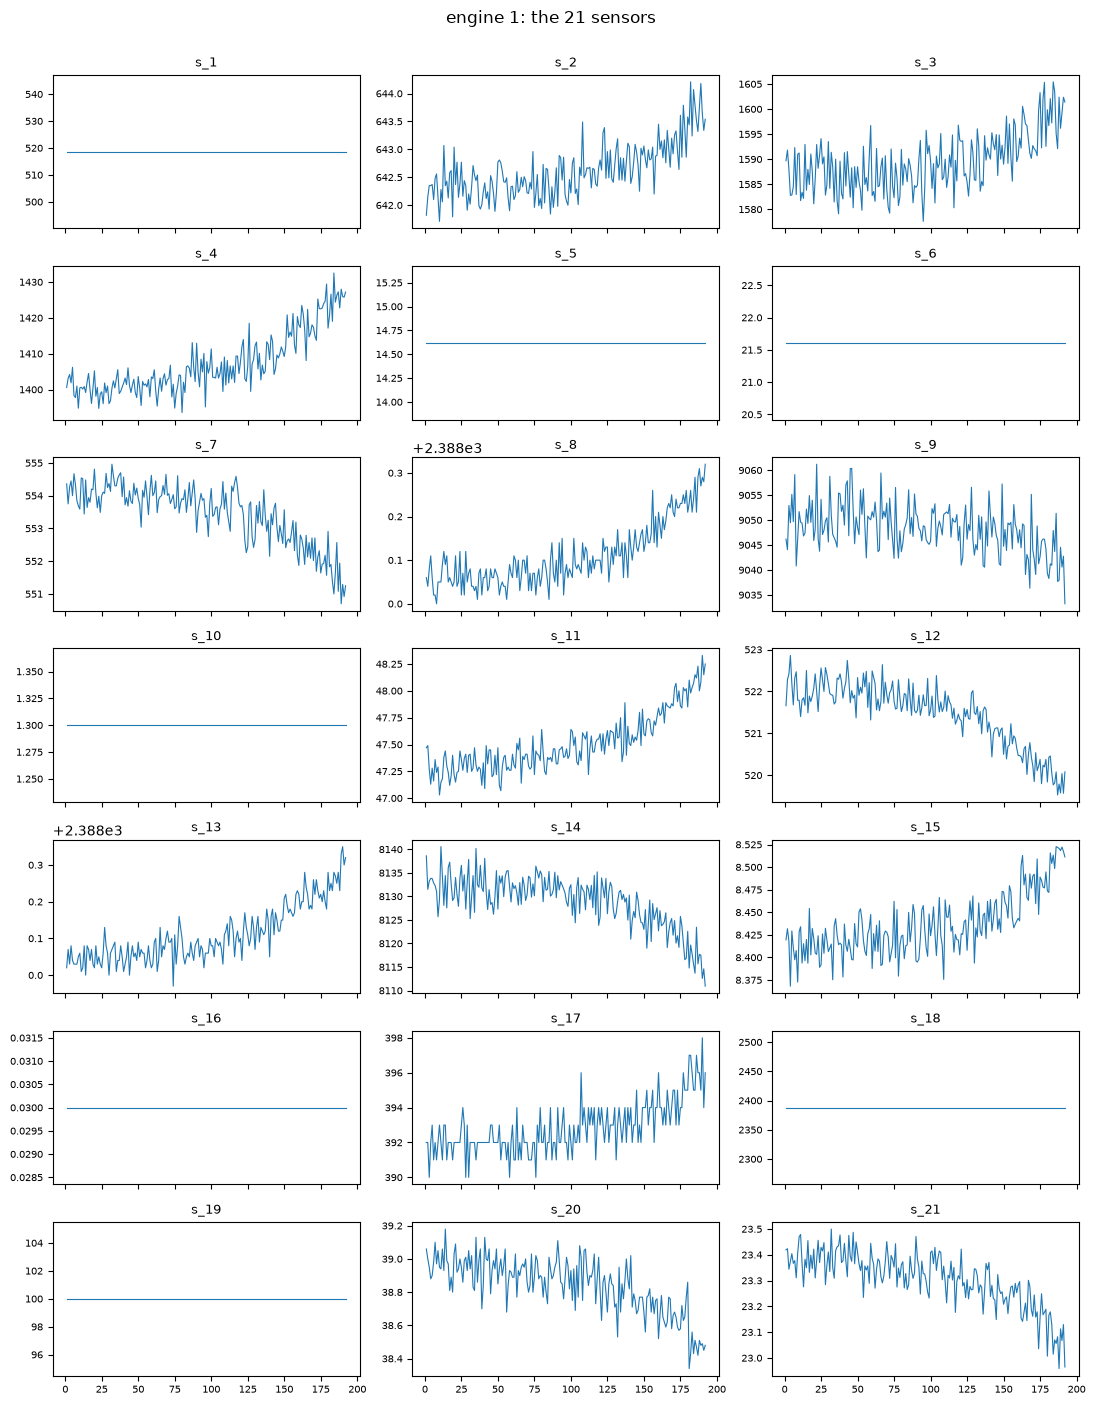

In [ ]:
unit_number = 1
engine = train[train["unit_id"] == unit_number]

fig, axes = plt.subplots(7, 3, figsize=(11, 14), sharex=True)
for ax, sensor in zip(axes.flat, SENSOR_COLUMNS, strict=True):
    ax.plot(engine["cycle"], engine[sensor], linewidth=0.8)
    ax.set_title(sensor, fontsize=9)
    ax.tick_params(labelsize=7)
fig.suptitle(f"engine {unit_number}: the 21 sensors", y=1.0)
fig.tight_layout()
plt.show()

Three kinds of curves appear. Some sensors are flat lines (`s_1`, `s_5`, `s_10`,
`s_16`, `s_18`, `s_19`): they never change. Most others are noisy, and the noise hides a
slow trend that becomes visible over the last 50 cycles or so: some sensors rise (`s_4`,
`s_11`), others fall (`s_7`, `s_12`). `s_6` jumps between two values only.

## One sensor, ten engines, aligned on the failure

Engines have different lifetimes, so plotting them against `cycle` mixes young and old
engines. Here the x axis is the number of cycles left before failure (0 = last cycle),
which lines every engine up on its failure.

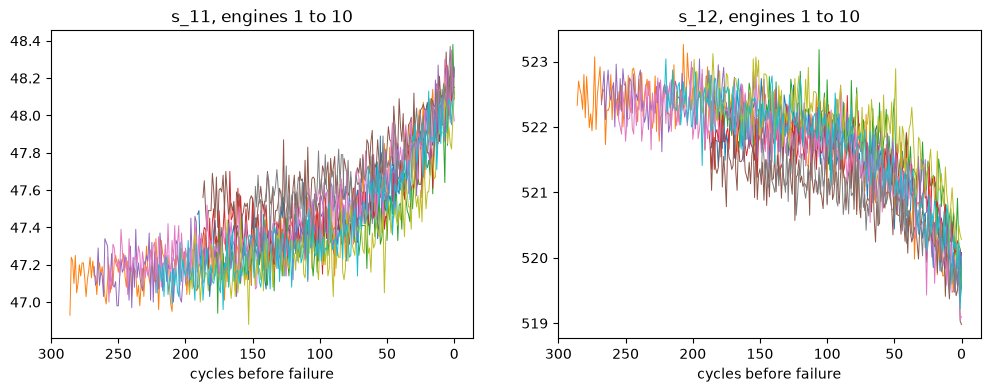

In [ ]:
train["cycles_to_failure"] = train.groupby("unit_id")["cycle"].transform("max") - train["cycle"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, sensor in zip(axes, ["s_11", "s_12"], strict=True):
    for unit_id in range(1, 11):
        engine = train[train["unit_id"] == unit_id]
        ax.plot(engine["cycles_to_failure"], engine[sensor], linewidth=0.7)
    ax.invert_xaxis()
    ax.set_xlabel("cycles before failure")
    ax.set_title(f"{sensor}, engines 1 to 10")
plt.show()

Once aligned on the failure, the ten engines tell the same story: `s_11` is almost flat
far from failure, rises slowly, then climbs fast over the last 50 cycles; `s_12` does the
opposite. Between 300 and about 150 cycles before failure, the noise is larger than the
trend. This is why, later, the remaining life will be capped: above some value, the
sensors simply do not say how much life is left.

## Which sensors never change?

A column with a single value carries no information for a model. The number of distinct
values and the standard deviation of each column find them.

In [ ]:
columns = ["setting_1", "setting_2", "setting_3"] + SENSOR_COLUMNS
summary = train[columns].agg(["nunique", "std"]).T
summary["std"] = summary["std"].round(5)
summary

,nunique,std
setting_1,158.0,0.00219
setting_2,13.0,0.00029
setting_3,1.0,0.00000
s_1,1.0,0.00000
s_2,310.0,0.50005
s_3,3012.0,6.13115
s_4,4051.0,9.00060
s_5,1.0,0.00000
s_6,2.0,0.00139
s_7,513.0,0.88509


In [ ]:
constant = summary.index[summary["nunique"] == 1].tolist()
print("one value only:", constant)
print("s_6 values:", train["s_6"].value_counts().to_dict())

kept = [sensor for sensor in SENSOR_COLUMNS if summary.loc[sensor, "nunique"] > 2]
print(f"{len(kept)} sensors kept:", kept)
print("same as params.yaml:", kept == load_params()["prepare"]["sensors"])

one value only: ['setting_3', 's_1', 's_5', 's_10', 's_16', 's_18', 's_19']
s_6 values: {21.61: 20225, 21.6: 406}
14 sensors kept: ['s_2', 's_3', 's_4', 's_7', 's_8', 's_9', 's_11', 's_12', 's_13', 's_14', 's_15', 's_17', 's_20', 's_21']
same as params.yaml: True


Six sensors and `setting_3` have one value only. `s_6` takes two values, 21.61 on 98 %
of rows and 21.60 on the rest: a rounding effect, not a trend. Leaving out these seven
sensors gives the 14 listed in `params.yaml` (a test in `tests/test_data.py` checks the
same thing).

## Correlation between the 14 sensors

The correlation goes from -1 to 1: close to 1, two sensors rise together; close to -1,
one rises when the other falls; close to 0, no linear link.

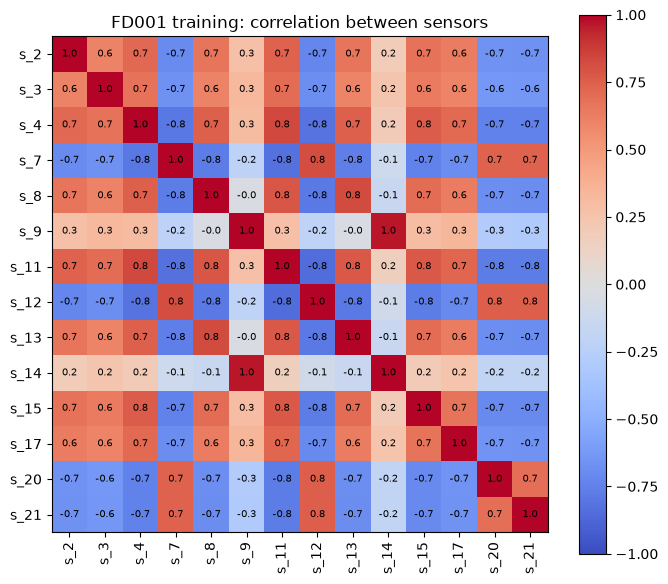

In [ ]:
sensors = load_params()["prepare"]["sensors"]
correlation = train[sensors].corr()

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(sensors)), sensors, rotation=90)
ax.set_yticks(range(len(sensors)), sensors)
for i in range(len(sensors)):
    for j in range(len(sensors)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax)
ax.set_title("FD001 training: correlation between sensors")
plt.show()

Twelve of the 14 sensors are strongly correlated with each other (between 0.6 and 0.85
in absolute value): they all react to the same wear, some upwards, some downwards. `s_9`
and `s_14` form a separate pair, correlated at 0.96 with each other but at most 0.34 with
the rest. Strong
correlations mean the sensors partly repeat the same information; this will matter when
explaining the models (phase 9).

## FD001 compared with FD003

FD003 has the same flight conditions as FD001 but two possible fault modes instead of one.
The plot puts every row of both training files on the same axis (cycles before failure),
for three sensors.

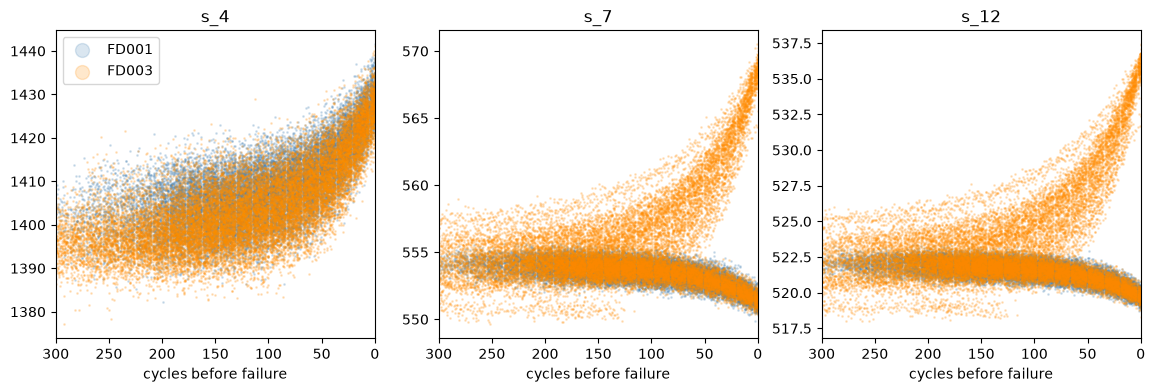

In [ ]:
fd003 = load_raw("FD003", "train")
fd003["cycles_to_failure"] = fd003.groupby("unit_id")["cycle"].transform("max") - fd003["cycle"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, sensor in zip(axes, ["s_4", "s_7", "s_12"], strict=True):
    for name, frame, colour in [("FD001", train, "steelblue"), ("FD003", fd003, "darkorange")]:
        ax.scatter(
            frame["cycles_to_failure"], frame[sensor], s=1, alpha=0.2, color=colour, label=name
        )
    ax.set_xlim(300, 0)
    ax.set_xlabel("cycles before failure")
    ax.set_title(sensor)
axes[0].legend(markerscale=10)
plt.show()

FD003 is drawn on top of FD001, so where the two files overlap only orange is visible.
For `s_4`, both files look alike. For `s_7` and `s_12`, the FD003 engines split into two
branches near failure: one follows FD001 downwards, the other rises (up to 570 for `s_7`,
against 556 at most in FD001). That is the
second fault mode. A model trained on FD001 has never seen this behaviour, which is why
FD003 will play the role of "new data" in the monitoring phase.

## What to keep for the next phases

- 100 training engines, followed until failure, living from 128 to 362 cycles.
- 7 of the 21 sensors are constant (or nearly) in FD001; the other 14 are kept.
- Sensors are noisy, and the wear stands out from the noise only in the last 100 to 150
  cycles: the target will
  be capped, and averages over several cycles will help the classic models.
- Engines must be compared by cycles before failure, not by cycle number.
- FD003 adds a second fault mode in which some sensors move the other way.